In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import tldextract
from sklearn.model_selection import StratifiedGroupKFold


In [36]:
file_path = "PhiUSIIL_Phishing_URL_Dataset.csv"
df_full = pd.read_csv(file_path, header=0)
df_full.head()

print(df_full.columns)


Index(['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP',
       'TLD', 'URLSimilarityIndex', 'CharContinuationRate',
       'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain',
       'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio',
       'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL',
       'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
       'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL',
       'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength',
       'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore',
       'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect',
       'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
       'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
       'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
       'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
       'NoOfEmptyRef', 'NoOf

In [37]:
#keep url related columns for EDA
url_features = ["URLLength", "Domain", "DomainLength", "IsDomainIP", "TLD", "NoOfSubDomain",
             "LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL", "IsHTTPS"]
df = df_full[["URL"] + url_features + ["label"]].copy()

print(f"\nShape: {df.shape}")
print(f"\nHead: {df.head()}")
print(f"\nType: \n{df.dtypes}")


Shape: (235795, 12)

Head:                                   URL  URLLength                      Domain  \
0    https://www.southbankmosaics.com         31    www.southbankmosaics.com   
1            https://www.uni-mainz.de         23            www.uni-mainz.de   
2      https://www.voicefmradio.co.uk         29      www.voicefmradio.co.uk   
3         https://www.sfnmjournal.com         26         www.sfnmjournal.com   
4  https://www.rewildingargentina.org         33  www.rewildingargentina.org   

   DomainLength  IsDomainIP  TLD  NoOfSubDomain  LetterRatioInURL  \
0            24           0  com              1             0.581   
1            16           0   de              1             0.391   
2            22           0   uk              2             0.517   
3            19           0  com              1             0.500   
4            26           0  org              1             0.606   

   DegitRatioInURL  SpacialCharRatioInURL  IsHTTPS  label  
0              0

In [ ]:
# check dataset features
print("URLLength == len(URL):", f"{(df['URL'].astype(str).str.len() == df['URLLength']).mean():.2%}")
print("Domain appears in URL:", np.mean([dm in u for dm, u in zip(df["Domain"], df["URL"])]))
print("IsHTTPS matches scheme:", (df["URL"].str.startswith("https") == df["IsHTTPS"].astype(bool)).mean())

URLLength == len(URL): 20.63%
Domain appears in URL: 1.0
IsHTTPS matches scheme: 0.9979092007888208


In [ ]:
# recompute features (since ~80% of URLLength do not match)
L = df["URL"].str.len()
df["URLLength"] = L
df["LetterRatioInURL"] = df["URL"].str.count(r"[A-Za-z]") / L
df["DegitRatioInURL"] = df["URL"].str.count(r"\d") / L
df["SpacialCharRatioInURL"] = 1 - df["LetterRatioInURL"] - df["DegitRatioInURL"]
df["IsHTTPS"] = df["URL"].str.startswith("https://").astype(int)

# Data Cleaning

In [39]:
#check missing
print(df.isna().sum())

URL                      0
URLLength                0
Domain                   0
DomainLength             0
IsDomainIP               0
TLD                      0
NoOfSubDomain            0
LetterRatioInURL         0
DegitRatioInURL          0
SpacialCharRatioInURL    0
IsHTTPS                  0
label                    0
dtype: int64


In [40]:
# check end slash 
df["d"] = df["URL"].str.len() - df["URLLength"]
df["ends_slash"] = df["URL"].str.endswith("/")
print(pd.crosstab([df["label"], df["ends_slash"]], df["d"]))

d                      0
label ends_slash        
0     False        64132
      True         36813
1     False       134850


In [41]:
# only phishing urls have end slash --> remove end slash for all
df["URL"] = df["URL"].str.replace(r"/+$", "", regex=True)
print("Ends with '/':", df.groupby("label")["URL"].apply(lambda s: s.str.endswith("/").mean()))

Ends with '/': label
0    0.0
1    0.0
Name: URL, dtype: float64


In [ ]:
#check empty and duplicates URLs
df["URL"] = df["URL"].astype(str).str.strip()

#invalid urls with whitespaces
edge_whitespace = (df["URL"] != df["URL"].str.strip()).sum()
df["URL"] = df["URL"].str.strip()
print("URLs with leading/trailing whitespace:", edge_whitespace)

inner_ws = df["URL"].str.contains(r"\s", regex=True)
print("URLs with internal whitespace:", inner_ws.sum())

print("Empty URLs:", df["URL"].eq("").sum())
print("Unique URLs:", df["URL"].nunique())
print("Duplicate URLs:", df.duplicated(subset="URL").sum())

URLs with leading/trailing whitespace: 0
URLs with internal whitespace: 0
Empty URLs: 0
Unique URLs: 234205
Duplicate rows: 425
Duplicate URLs: 1590


In [43]:
#check if any labels are diff for any duplicates
duplicates = df[df.duplicated(subset="URL", keep=False)] \
                .sort_values("URL")
label_counts = duplicates.groupby("URL")["label"].nunique()

conflicting_urls = label_counts[label_counts > 1]

print("URLs with conflicting labels:", len(conflicting_urls))
print(conflicting_urls)

URLs with conflicting labels: 1
URL
https://www.education.gouv.fr    2
Name: label, dtype: int64


In [44]:
#drop duplicates
df = df[~df["URL"].isin(conflicting_urls.index)]
df = df.drop_duplicates(subset = "URL", keep = "first").reset_index(drop = True)
print("Rows after removing duplicates:", len(df))
print("Duplicate URLs remaining:", df.duplicated(subset="URL").sum())

Rows after removing duplicates: 234204
Duplicate URLs remaining: 0


In [45]:
#drop near-duplicate urls: 
# - http vs https
# - lowercase hostname
# - www vs www2 etc.
# - remove trailing /

def normalise(u: str) -> str:
    s = re.sub(r"^[A-Za-z][A-Za-z0-9+.\-]*://", "", u)
    m = re.match(r"([^/?#]*)(.*)", s)
    host, rest = m.group(1).lower(), m.group(2)
    host = re.sub(r"^www\d*\.", "", host)
    return host + rest

df["normalised"] = df["URL"].map(normalise)

# normalised urls wiht conflicting labels
g = df.groupby("normalised")["label"].nunique()
conflict_keys = g[g > 1].index
print("Normalised URLs with conflicting labels:", len(conflict_keys))


df = df[~df["normalised"].isin(conflict_keys)]
df = df.drop_duplicates(subset="normalised", keep="first").reset_index(drop=True)
print("Rows after removing duplicates:", len(df))


Normalised URLs with conflicting labels: 42
Rows after removing duplicates: 231747


# Train-Validation-Test Split 
- 80% train, 10% validation, 10% test 
- grouped by domain --> prevent model from memorising domain information (eg. ensure `a.firebaseapp.com` and `b.firebaseapp.com` are in the same split)
- stratify on label

In [55]:
ext = tldextract.TLDExtract(suffix_list_urls=()) 
def reg_domain(host):
    e = ext(host)
    return ".".join(x for x in (e.domain, e.suffix) if x) or host

host_map = {h: reg_domain(h) for h in df["Domain"].unique()}
df["group"] = df["Domain"].map(host_map)

df["split"] = "train"
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
for k, (_, idx) in enumerate(sgkf.split(df, df["label"], groups=df["group"])):
    if k == 0: df.loc[df.index[idx], "split"] = "test"
    if k == 1: df.loc[df.index[idx], "split"] = "val"

sets = {s: set(df.loc[df.split == s, "group"]) for s in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"] or sets["train"] & sets["test"] or sets["val"] & sets["test"]), "domain leakage!"
print("No registered domain appears in more than one split.")

top = df.groupby("group").size().sort_values(ascending=False)
print("Largest domains:", top.head(5).to_dict())
print("Largest domains pct:", (top.head(20) / len(df)).to_dict()) # check if any domains are dominating


No registered domain appears in more than one split.
Largest domains: {'web.app': 5605, 'firebaseapp.com': 5446, 'repl.co': 3582, 'weeblysite.com': 2889, 'ipfs.io': 1437}
Largest domains pct: {'web.app': 0.0241858578536076, 'firebaseapp.com': 0.023499764829749685, 'repl.co': 0.015456510763893384, 'weeblysite.com': 0.012466180791984362, 'ipfs.io': 0.006200727517508317, 'workers.dev': 0.005799427824308406, 'square.site': 0.004414296625199031, 'xsph.ru': 0.004004366831070089, 'dweb.link': 0.0037238885508766024, 'pantheonsite.io': 0.003611697238799208, 'google.com': 0.0033700544127863575, 'godaddysites.com': 0.0031586169400251137, 'duckdns.org': 0.002692591489857474, 'weebly.com': 0.002299921897586592, 'webwave.dev': 0.0022654014938704708, 'glitch.me': 0.0021316349294705, 'cf-ipfs.com': 0.002084169374360833, 'fleek.co': 0.0019806081632124687, 'wixsite.com': 0.0019547178604253776, 'tw1.ru': 0.0017475954381286488}


In [56]:
split_tbl = df.groupby("split").agg(rows=("URL", "size"), phishing_pct=("label", lambda s: round(100 * (1 - s.mean()), 1)))
split_tbl

,rows,phishing_pct
split,,
test,23175,41.8
train,185397,41.8
val,23175,41.8


# EDA (on Train)

             Count  Percentage
label                         
Legitimate  134807   58.169901
Phishing     96940   41.830099


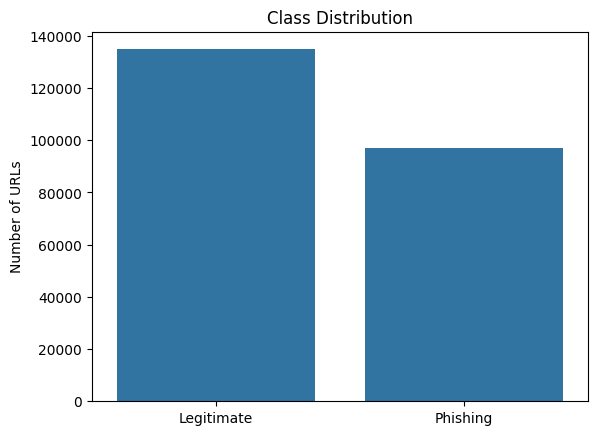

In [58]:
#check for class distributions (helps to explain metrics??)
class_counts = (
    df["label"]
    .value_counts()
    .rename(index={0: "Phishing", 1: "Legitimate"})
)

class_percent = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .rename(index={0: "Phishing", 1: "Legitimate"})
)

print(pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent
}))

sns.countplot(
    data=df.assign(
        Class=df["label"].map({0: "Phishing", 1: "Legitimate"})
    ),
    x="Class"
)
plt.title("Class Distribution")
plt.xlabel("")
plt.ylabel("Number of URLs")
plt.show()

In [ ]:
#do we parse URL into modifiable components?

In [ ]:
#analyse URL (check original dataset idk what stuff to keep/throw yet)
#basic stuff (url length, digit count, letter count, special count -> eda by ratio? summary by class?
#url length distribution 
#character vocabulary
#URL component analysis

In [ ]:
#check for domain leakage before split (???)

In [ ]:
#analyse what parts can be manipulated adverserially

In [ ]:
#see how edit budget affect URL length...